In [35]:
# --- Standard library ---
import os
import re
import json
from collections import defaultdict

# --- Numerical ---
import numpy as np

# --- SVG parsing ---
from svgpathtools import svg2paths2

# --- Geometry ---
from shapely.geometry import Polygon as ShapelyPolygon

# --- Rendering ---
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon
from matplotlib.collections import PatchCollection
import random


In [21]:
def extract_color(attr):
    """
    Extract fill or stroke color from SVG attributes.
    Supports hex and rgb() styles from CorelDRAW.
    """

    # Direct attributes
    if attr.get("fill") and attr["fill"] != "none":
        return attr["fill"]

    if attr.get("stroke") and attr["stroke"] != "none":
        return attr["stroke"]

    style = attr.get("style", "")

    # Hex colors
    m = re.search(r"fill:\s*(#[0-9A-Fa-f]{6})", style)
    if m:
        return m.group(1)

    m = re.search(r"stroke:\s*(#[0-9A-Fa-f]{6})", style)
    if m:
        return m.group(1)

    # rgb() colors (Corel)
    m = re.search(r"(fill|stroke):\s*rgb\([^)]+\)", style)
    if m:
        return m.group(0)  # use full rgb(...) string as key

    return None


In [11]:
def parse_filename(filename):
    """
    JB_FRONT_16-18-20.svg  → sizes = ['16','18','20']
    JB_FRONT_M-L-XL.svg    → sizes = ['M','L','XL']
    """

    name = os.path.splitext(filename)[0]

    parts = name.split("_")
    if len(parts) < 3:
        raise ValueError(f"Invalid filename format: {filename}")

    brand = parts[0]
    part = parts[1].upper()
    size_list = parts[2]

    sizes = size_list.split("-")

    return part, sizes


In [3]:
def svg_path_to_polygon(path, svg_attr, samples=40):
    # --- Parse viewBox ---
    vb_x, vb_y, vb_w, vb_h = map(float, svg_attr["viewBox"].split())

    # --- Parse physical size in mm ---
    width_mm = float(svg_attr["width"].replace("mm", ""))
    height_mm = float(svg_attr["height"].replace("mm", ""))

    scale_x = width_mm / vb_w
    scale_y = height_mm / vb_h

    raw = []
    for seg in path:
        for t in np.linspace(0, 1, samples):
            pt = seg.point(t)
            raw.append((pt.real, pt.imag))

    # Convert to inches
    pts = []
    for x, y in raw:
        x_mm = (x - vb_x) * scale_x
        y_mm = (y - vb_y) * scale_y
        pts.append((x_mm / 25.4, y_mm / 25.4))

    # Flip Y and normalize
    max_y = max(y for _, y in pts)
    pts = [(x, max_y - y) for x, y in pts]

    min_x = min(x for x, _ in pts)
    min_y = min(y for _, y in pts)
    pts = [(x - min_x, y - min_y) for x, y in pts]

    return pts


In [22]:
def load_svg_file(svg_path):
    paths, attrs, svg_attr = svg2paths2(svg_path)

    colored_groups = defaultdict(list)
    uncolored_paths = []

    for path, attr in zip(paths, attrs):
        color = extract_color(attr)

        if color is None:
            uncolored_paths.append(path)
        else:
            colored_groups[color].append(path)

    polygons = []

    # --- Case 1: Colored grouping works ---
    if colored_groups:
        for color, group in colored_groups.items():
            pts = []
            for p in group:
                pts.extend(svg_path_to_polygon(p, svg_attr))
            poly = Polygon(pts)
            polygons.append(poly)

    # --- Case 2: Fallback – no colors usable ---
    else:
        # Each path assumed to be one size
        for p in paths:
            pts = svg_path_to_polygon(p, svg_attr)
            poly = Polygon(pts)
            if poly.area > 1e-3:
                polygons.append(poly)

    if not polygons:
        raise ValueError(f"No valid polygons found in {svg_path}")

    return polygons


In [14]:
def assign_sizes(polygons, sizes):
    assert len(polygons) == len(sizes), (
        f"Size count mismatch: {len(polygons)} polygons vs {len(sizes)} sizes"
    )

    areas = [(poly.area, poly) for poly in polygons]
    areas.sort(key=lambda x: x[0])  # smallest → largest
    validate_monotonic_areas(polygons)
    result = []
    for size, (_, poly) in zip(sizes, areas):
        result.append((size, list(poly.exterior.coords)))

    return result


In [13]:
def validate_monotonic_areas(polygons):
    areas = sorted(poly.area for poly in polygons)
    for i in range(len(areas) - 1):
        ratio = areas[i + 1] / areas[i]
        if ratio < 1.02:
            raise ValueError(
                "Two sizes have nearly identical area. "
                "Check colors or duplicate patterns."
            )


In [6]:
def process_design_folder(folder_path):
    all_shapes = []

    for file in os.listdir(folder_path):
        if not file.lower().endswith(".svg"):
            continue

        part, sizes = parse_filename(file)
        svg_path = os.path.join(folder_path, file)

        polygons = load_svg_file(svg_path)
        sized_polys = assign_sizes(polygons, sizes)

        for size, poly in sized_polys:
            all_shapes.append({
                "part": part,
                "size": size,
                "polygon": poly
            })

    # Save structured output
    out_path = os.path.join(folder_path, "parsed_shapes.json")
    with open(out_path, "w") as f:
        json.dump(all_shapes, f, indent=2)

    return all_shapes


In [26]:
def evaluate_kpis(placed_shapes, strip_width):
    max_y = 0.0
    used_area = 0.0

    for item in placed_shapes:
        poly = item["polygon"]

        for _, y in poly:
            max_y = max(max_y, y)

        area = 0.0
        n = len(poly)
        for i in range(n):
            x1, y1 = poly[i]
            x2, y2 = poly[(i + 1) % n]
            area += (x1 * y2 - x2 * y1)
        used_area += abs(area) / 2.0

    total_area = strip_width * max_y
    empty_ratio = 1.0 - (used_area / total_area) if total_area > 0 else 0.0

    return {
        "layer_length_in": max_y,
        "used_area_in2": used_area,
        "total_area_in2": total_area,
        "empty_ratio": empty_ratio
    }


In [25]:
def phase1_packer(shapes, strip_width):
    shapes = sorted(
        shapes,
        key=lambda s: max(x for x, _ in s["polygon"]),
        reverse=True
    )

    placed = []
    x_cursor = 0.0
    y_cursor = 0.0
    row_height = 0.0

    for item in shapes:
        poly = item["polygon"]

        max_x = max(x for x, _ in poly)
        max_y = max(y for _, y in poly)

        if x_cursor + max_x > strip_width:
            x_cursor = 0.0
            y_cursor += row_height
            row_height = 0.0

        placed_poly = [(x + x_cursor, y + y_cursor) for x, y in poly]

        placed.append({
            "polygon": placed_poly,
            "part": item["part"],
            "size": item["size"]
        })

        x_cursor += max_x
        row_height = max(row_height, max_y)

    return placed


In [37]:
def render_marker(
    placed_shapes,
    strip_width,
    title=None,
    save_path=None,      # NEW
    dpi=300              # NEW
):
    """
    Render a fabric marker layout with part + size labels.

    save_path: str or None
        e.g. "marker.png" or "marker.pdf"
    """

    fig, ax = plt.subplots(figsize=(10, 14))

    patches = []
    colors = []
    part_colors = {}

    def get_color(part):
        if part not in part_colors:
            part_colors[part] = (
                random.random(),
                random.random(),
                random.random(),
                0.6
            )
        return part_colors[part]

    max_y = 0.0

    for item in placed_shapes:
        poly = item["polygon"]
        part = item["part"]
        size = item["size"]

        patch = Polygon(poly)

        patches.append(patch)
        colors.append(get_color(part))

        # centroid label
        cx = sum(p[0] for p in poly) / len(poly)
        cy = sum(p[1] for p in poly) / len(poly)

        ax.text(
            cx, cy,
            f"{part}\n{size}",
            ha="center",
            va="center",
            fontsize=8,
            fontweight="bold"
        )

        for _, y in poly:
            max_y = max(max_y, y)

    collection = PatchCollection(
        patches,
        facecolors=colors,
        edgecolors="black",
        linewidths=0.8
    )
    ax.add_collection(collection)

    # Fabric boundary
    ax.plot([0, strip_width], [0, 0], color="black", linewidth=2)
    ax.plot([0, strip_width], [max_y, max_y], color="black", linewidth=2)
    ax.plot([0, 0], [0, max_y], color="black", linewidth=2)
    ax.plot([strip_width, strip_width], [0, max_y], color="black", linewidth=2)

    ax.set_xlim(0, strip_width)
    ax.set_ylim(0, max_y)
    ax.set_aspect("equal")
    ax.set_xlabel("Fabric Width (in)")
    ax.set_ylabel("Fabric Length (in)")

    if title:
        ax.set_title(title)

    plt.tight_layout()

    # ✅ SAVE HERE
    if save_path:
        plt.savefig(save_path, dpi=dpi, bbox_inches="tight")

    plt.show()
    plt.close(fig)

In [27]:
STRIP_WIDTH = 36.0  # inches

design_folder = "JK-123"

shapes = process_design_folder(design_folder)

placed_phase1 = phase1_packer(shapes, STRIP_WIDTH)
kpis_phase1 = evaluate_kpis(placed_phase1, STRIP_WIDTH)

for k, v in kpis_phase1.items():
    print(f"{k}: {v:.3f}")


layer_length_in: 46.622
used_area_in2: 1271.603
total_area_in2: 1678.406
empty_ratio: 0.242


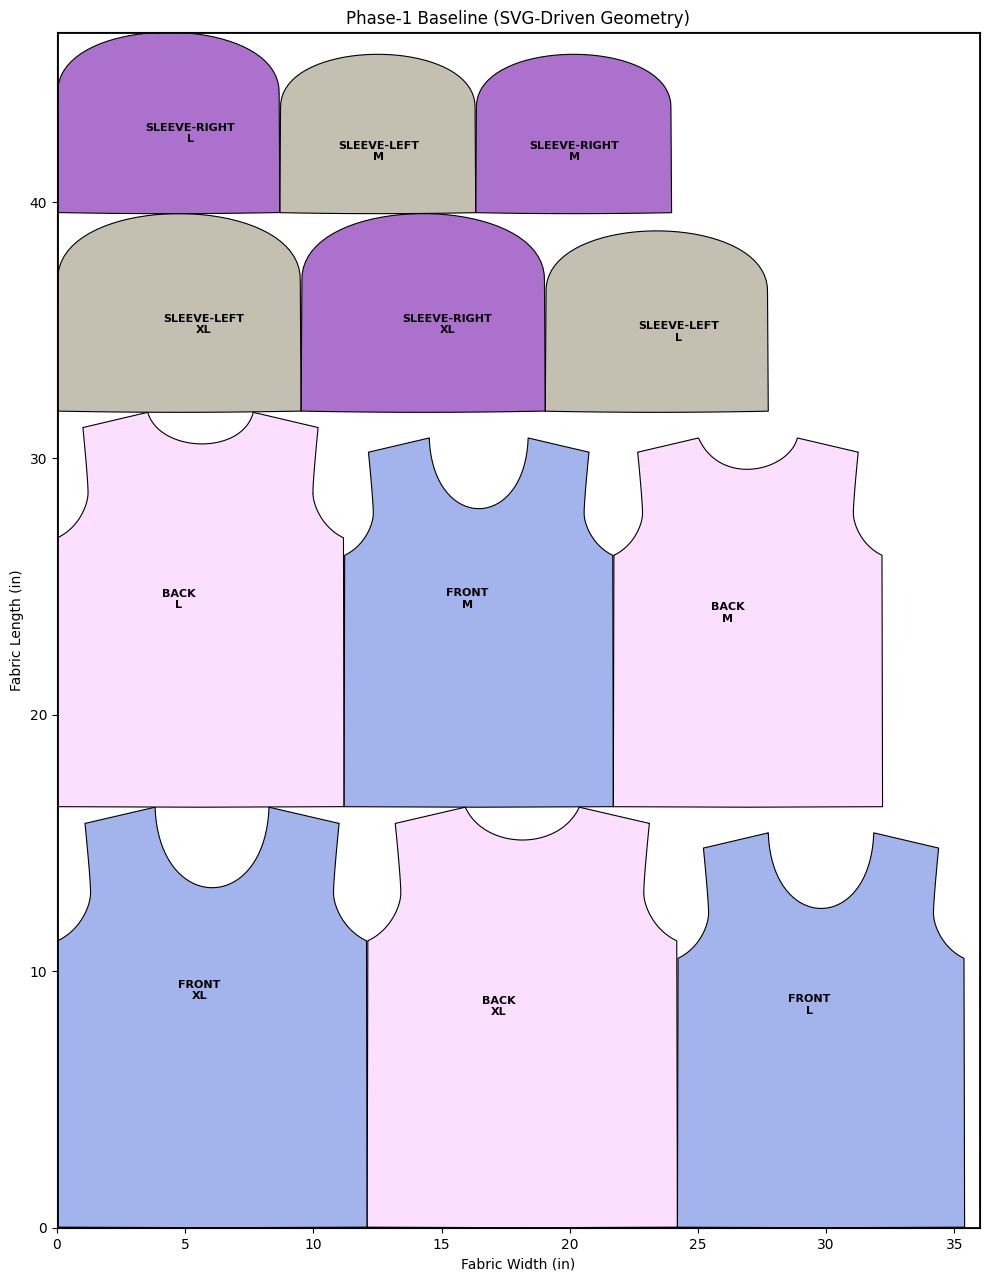

In [38]:
render_marker(
    placed_phase1,
    strip_width=STRIP_WIDTH,
    title="Phase-1 Baseline (SVG-Driven Geometry)",
    save_path="JK-123/phase1_baseline_marker.png"
)


In [24]:
shapes

[{'part': 'BACK',
  'size': 'M',
  'polygon': [(6.661338147750939e-16, 0.019826752631061595),
   (0.1346152042516825, 0.019318374358473278),
   (0.26923040850336455, 0.018809996085879632),
   (0.4038456127550465, 0.018301617813287763),
   (0.5384608170067282, 0.017793239540694117),
   (0.6730760212584102, 0.0172848612681058),
   (0.8076912255100923, 0.01677648299551393),
   (0.9423064297617738, 0.01626810472292206),
   (1.076921634013456, 0.015759726450331968),
   (1.2115368382651381, 0.015251348177741875),
   (1.3461520425168196, 0.014742969905148229),
   (1.4807672467685016, 0.014234591632558136),
   (1.615382451020184, 0.013726213359966266),
   (1.7499976552718655, 0.013217835087374397),
   (1.8846128595235478, 0.01270945681478608),
   (2.0192280637752296, 0.012201078542192434),
   (2.153843268026912, 0.011692700269600564),
   (2.2884584722785934, 0.011184321997006919),
   (2.423073676530275, 0.010675943724418602),
   (2.5576888807819564, 0.010167565451826732),
   (2.692304085033639